In [1]:
import numpy as np
import pandas as pd
import itertools
import scipy.stats
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import MultipleLocator
from scipy.stats.mstats import zscore
import matplotlib.gridspec as gridspec
import statsmodels.api as sm
from tqdm import tqdm

# Load data

In [2]:
savepath = 'F:/A J YANG PAPER/1stRound/Recollaboration/Figs/Nobel/'

In [3]:
def set_fig_(ax , xlabel=0, ylabel=0 , xlog=0, ylog=0, fontsize=16, iflegend=0, legendloc=2):
    if xlabel!=0:
        ax.set_xlabel(xlabel,size = fontsize)
    else:
        ax.set_xlabel('')
    if ylabel!=0:
        ax.set_ylabel(ylabel,size = fontsize)
    else:
        ax.set_ylabel('')
    if ylog:
        ax.set_yscale("log")
    if xlog:
        ax.set_xscale("log")
    if iflegend==1:
        ax.legend(frameon =False,fontsize = fontsize, loc=legendloc)
    if iflegend==2:
        ax.legend(frameon =False,fontsize = fontsize,ncol=1,bbox_to_anchor=(1, 0), loc=3, borderaxespad=0)
    ax.tick_params(axis='x',labelsize=fontsize)
    ax.tick_params(axis='y',labelsize=fontsize)
    plt.tick_params(axis='both', which='major', labelsize=16)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_linewidth(2)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

In [4]:
def set_fig_2(ax , xlabel=0, ylabel=0 , xlog=0, ylog=0, fontsize=16, iflegend=0, legendloc=2):
    if xlabel!=0:
        ax.set_xlabel(xlabel,size = fontsize)
    else:
        ax.set_xlabel('')
    if ylabel!=0:
        ax.set_ylabel(ylabel,size = fontsize)
    else:
        ax.set_ylabel('')
    if ylog:
        ax.set_yscale("log")
    if xlog:
        ax.set_xscale("log")
    if iflegend==1:
        ax.legend(frameon =False,fontsize = fontsize, loc=legendloc)
    if iflegend==2:
        ax.legend(frameon =False,fontsize = fontsize,ncol=1,bbox_to_anchor=(1, 0), loc=3, borderaxespad=0)
    ax.tick_params(axis='x',labelsize=fontsize)
    ax.tick_params(axis='y',labelsize=fontsize)
    plt.tick_params(axis='both', which='major', labelsize=16)
    ax.spines['bottom'].set_linewidth(2)
    ax.spines['left'].set_linewidth(2)
    ax.spines["right"].set_linewidth(2)
    ax.spines["top"].set_linewidth(2)

In [15]:
def draw_p(data,col):
    t, p = scipy.stats.ttest_ind(data[data['Nobel_paper']==1][col].dropna(), data[data['Nobel_paper']==0][col].dropna(), equal_var=False, alternative='two-sided')
    if p>=0.05:
        ptext = 'p = '+str(np.around(p, 3))
    elif p<0.001:
        ptext = 'p < 0.001'
    elif p<0.01:
        ptext = 'p < 0.01'
    elif p<0.05:
        ptext = 'p < 0.05'


    b = max(np.mean(data[data['Nobel_paper']==0][col]) , np.mean(data[data['Nobel_paper']==1][col]))
    
    plt.text(0, np.mean(data[data['Nobel_paper']==0][col]) - b*0.1, 
             "{}".format(np.around(np.mean(data[data['Nobel_paper']==0][col]), 1)),c = 'white', fontsize=16, ha='center', fontweight='bold')
    plt.text(1, np.mean(data[data['Nobel_paper']==1][col]) - b*0.1,
             "{}".format(np.around(np.mean(data[data['Nobel_paper']==1][col]), 1)),c = 'white', fontsize=16, ha='center', fontweight='bold')
    
    plt.text(-0.1, b*1.15, "Welch's T = {}".format(np.around(t, 2)), fontsize=16)
    plt.text(0.15, b*1.05, ptext, fontsize=16)

In [16]:
def draw_p2(data,col):
    t, p = scipy.stats.ttest_ind(data[data['Nobel_paper']==1][col].dropna(), data[data['Nobel_paper']==0][col].dropna(), equal_var=False, alternative='two-sided')
    if p>=0.05:
        ptext = 'p = '+str(np.around(p, 3))
    elif p<0.001:
        ptext = 'p < 0.001'
    elif p<0.01:
        ptext = 'p < 0.01'
    elif p<0.05:
        ptext = 'p < 0.05'


    b = max(np.mean(data[data['Nobel_paper']==0][col]) , np.mean(data[data['Nobel_paper']==1][col]))
    
    plt.text(0, np.mean(data[data['Nobel_paper']==0][col]) - b*0.1, 
             "{}".format(np.around(np.mean(data[data['Nobel_paper']==0][col]), 2)),c = 'white', fontsize=16, ha='center', fontweight='bold')
    plt.text(1, np.mean(data[data['Nobel_paper']==1][col]) - b*0.1,
             "{}".format(np.around(np.mean(data[data['Nobel_paper']==1][col]), 2)),c = 'white', fontsize=16, ha='center', fontweight='bold')
    
    plt.text(-0.1, b*1.15, "Welch's T = {}".format(np.around(t, 2)), fontsize=16)
    plt.text(0.15, b*1.05, ptext, fontsize=16)

# Is Nobel Prize a repeat collaboration?

In [7]:
df = pd.read_csv(r"E:\Data\SciSciNet\Paper\Nobel\Nobel Laureates\NobelCoauthors_.csv.zip")

In [8]:
df.columns

Index(['Focal_AID', 'AuthorID', 'PaperID', 'Year', 't', 'Nobel_paper',
       'Reference_Count', 'Team_Size', 't_start', 't_end', 'l', 'k', 'r_k',
       'cum_k', 'b_cum_k', 'delta_t', 'age_diff', 'coau_Productivity',
       'fau_Productivity', 'coau_h', 'coau_cit', 'fau_h', 'fau_cit',
       'strong_tie', 'paper_RaoStirling', 'paper_cit', 'paper_cit5',
       'paper_CD', 'paper_CD5', 'cit_pct', 'CD_pct', 'Novelty_pct', 'Field'],
      dtype='object')

In [9]:
df['repeat'] = df['b_cum_k'].apply(lambda x:1 if x>0 else 0)

In [10]:
df1 = df[df['Nobel_paper']==1].copy()
df1.index = range(len(df1))
df_contorl_t = df.merge(df1[['Focal_AID' , 't', 'paper_CD5']] , on = ['Focal_AID' , 't'])

In [11]:
df_ = df.groupby(['Focal_AID', 'Field', 'Nobel_paper' , 'PaperID'])['b_cum_k'].mean().reset_index()
df_contorl_t_ = df_contorl_t.groupby(['Focal_AID', 'Field', 'Nobel_paper' , 'PaperID'])['b_cum_k'].mean().reset_index()

In [12]:
df__ = df.groupby(['Focal_AID', 'Field', 'Nobel_paper' , 'PaperID'])['repeat'].mean().reset_index()
df_contorl_t__ = df_contorl_t.groupby(['Focal_AID', 'Field', 'Nobel_paper' , 'PaperID'])['repeat'].mean().reset_index()

C:\Users\nd\AppData\Local\Temp\ipykernel_4520\1546919419.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Nobel_paper', y = 'repeat', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=['k','tab:red'])
C:\Users\nd\AppData\Local\Temp\ipykernel_4520\1546919419.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df[df['Field']==field], x='Nobel_paper', y = 'repeat', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=[colors[i],'tab:red'])
C:\Users\nd\AppData\Local\Temp\ipykernel_4520\1546919419.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=Fal

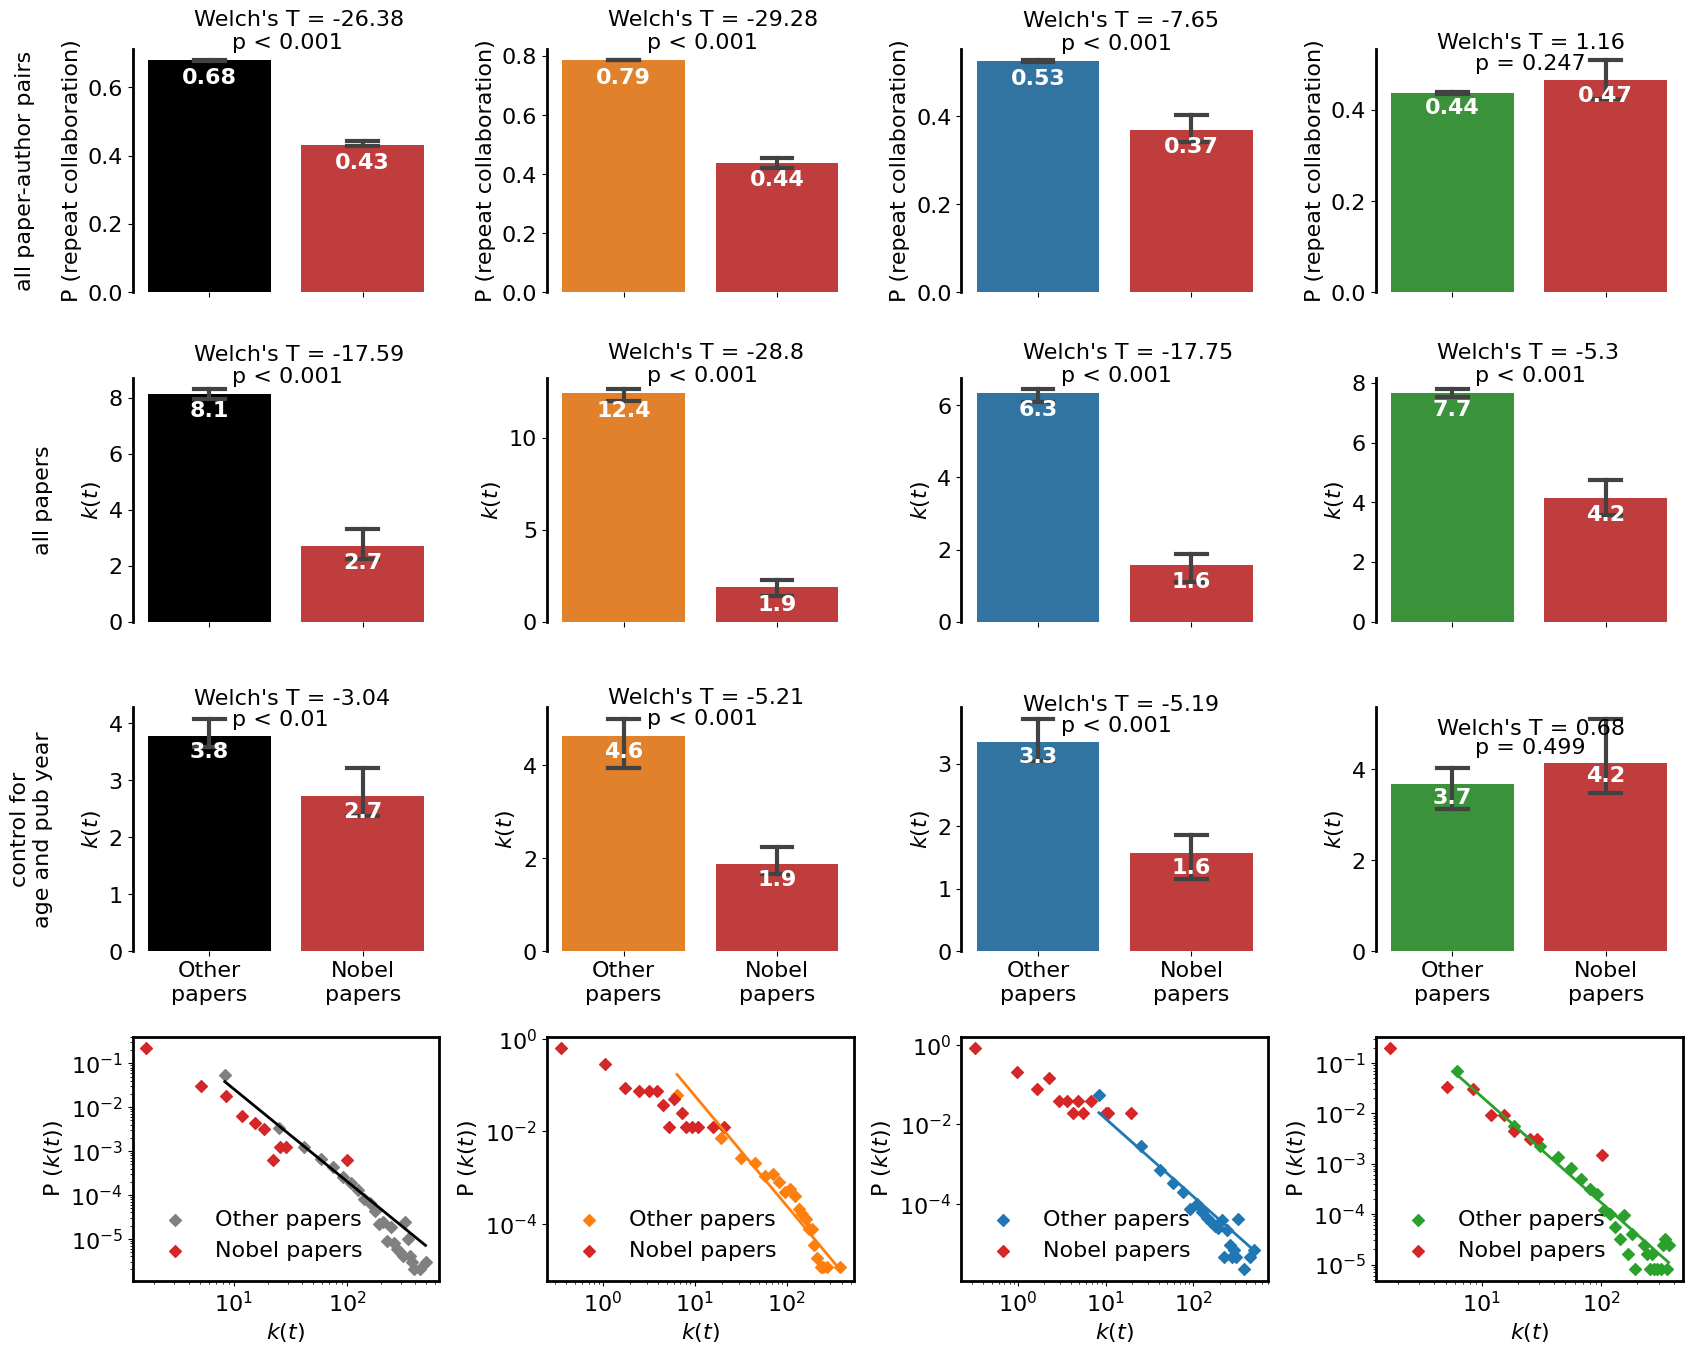

In [17]:
colors = ['tab:orange','tab:blue','tab:green']
fig = plt.figure(figsize=(20 , 16))
gs = gridspec.GridSpec(4, 4, figure=fig, wspace=.35, hspace=.35)
ax = fig.add_subplot(gs[0])
sns.barplot(data=df, x='Nobel_paper', y = 'repeat', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=['k','tab:red'])
plt.xticks([0,1],['',''])
draw_p2(df,'repeat')
set_fig_(ax , xlabel=0, ylabel='all paper-author pairs\n\nP (repeat collaboration)', xlog=0, ylog=0)

for i,field in enumerate(['Physics','Chemistry','Medicine']):
    ax = fig.add_subplot(gs[i+1])
    sns.barplot(data=df[df['Field']==field], x='Nobel_paper', y = 'repeat', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=[colors[i],'tab:red'])
    plt.xticks([0,1],['',''])
    draw_p2(df[df['Field']==field],'repeat')
    set_fig_(ax , xlabel=0, ylabel='P (repeat collaboration)', xlog=0, ylog=0)
    
##-------------------------------------------------------------
ax = fig.add_subplot(gs[4])
sns.barplot(data=df_, x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=['k','tab:red'])
plt.xticks([0,1],['',''])
draw_p(df_,'b_cum_k')
set_fig_(ax , xlabel=0, ylabel='all papers\n\n$k(t)$', xlog=0, ylog=0)

for i,field in enumerate(['Physics','Chemistry','Medicine']):
    ax = fig.add_subplot(gs[i+5])
    sns.barplot(data=df_[df_['Field']==field], x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=[colors[i],'tab:red'])
    plt.xticks([0,1],['',''])
    # plt.ylim(0,40)
    draw_p(df_[df_['Field']==field],'b_cum_k')
    set_fig_(ax , xlabel=0, ylabel='$k(t)$', xlog=0, ylog=0)

##----------------------------------------------------------------
ax = fig.add_subplot(gs[8])
sns.barplot(data=df_contorl_t_, x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=['k','tab:red'])
plt.xticks([0,1],['Other\npapers','Nobel\npapers'])
draw_p(df_contorl_t_,'b_cum_k')
set_fig_(ax , xlabel=0, ylabel='control for\nage and pub year\n\n$k(t)$', xlog=0, ylog=0)

for i,field in enumerate(['Physics','Chemistry','Medicine']):
    ax = fig.add_subplot(gs[i+9])
    sns.barplot(data=df_contorl_t_[df_contorl_t_['Field']==field], x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=[colors[i],'tab:red'])
    plt.xticks([0,1],['Other\npapers','Nobel\npapers'])
    draw_p(df_contorl_t_[df_contorl_t_['Field']==field],'b_cum_k')
    set_fig_(ax , xlabel=0, ylabel='$k(t)$', xlog=0, ylog=0)

##----------------------------------------------------------------
ax = fig.add_subplot(gs[12])
hist_values, bin_edges = np.histogram(df_[df_['Nobel_paper']==0]['b_cum_k'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='grey', marker='D', label='Other papers')
regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
plt.plot(bin_centers, fitted_line, color='k', linestyle='-', lw = 2)

hist_values, bin_edges = np.histogram(df_[df_['Nobel_paper']==1]['b_cum_k'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='tab:red', marker='D', label='Nobel papers')
# regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
# fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
# plt.plot(bin_centers, fitted_line, color='red', linestyle='-', lw = 2, label='Log-log fit')
set_fig_2(ax , xlabel='$k(t)$', ylabel='P ($k(t)$)', xlog=1, ylog=1, iflegend=1, legendloc=3)

for i,field in enumerate(['Physics','Chemistry','Medicine']):
    ax = fig.add_subplot(gs[i+13])
    hist_values, bin_edges = np.histogram(df_[df_['Field']==field][df_['Nobel_paper']==0]['b_cum_k'].values, bins=30, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    plt.scatter(bin_centers, hist_values, color=colors[i], marker='D', label='Other papers')
    regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
    fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
    plt.plot(bin_centers, fitted_line, color=colors[i], linestyle='-', lw = 2)
    
    hist_values, bin_edges = np.histogram(df_[df_['Field']==field][df_['Nobel_paper']==1]['b_cum_k'].values, bins=30, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    plt.scatter(bin_centers, hist_values, color='tab:red', marker='D', label='Nobel papers')
    set_fig_2(ax , xlabel='$k(t)$', ylabel='P ($k(t)$)', xlog=1, ylog=1, iflegend=1, legendloc=3)

plt.savefig(savepath+"Nobel_papers_show_lower_k.svg",bbox_inches = 'tight')

## Subfig

C:\Users\nd\AppData\Local\Temp\ipykernel_17452\3719183371.py:23: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  hist_values, bin_edges = np.histogram(df_[df_['Field']==field][df_['Nobel_paper']==0]['b_cum_k'].values, bins=30, density=True)
C:\Users\nd\AppData\Local\Temp\ipykernel_17452\3719183371.py:30: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  hist_values, bin_edges = np.histogram(df_[df_['Field']==field][df_['Nobel_paper']==1]['b_cum_k'].values, bins=30, density=True)
C:\Users\nd\AppData\Local\Temp\ipykernel_17452\3719183371.py:23: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  hist_values, bin_edges = np.histogram(df_[df_['Field']==field][df_['Nobel_paper']==0]['b_cum_k'].values, bins=30, density=True)
C:\Users\nd\AppData\Local\Temp\ipykernel_17452\3719183371.py:30: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  hist_values, bin_edges = np.histogram(df_[df

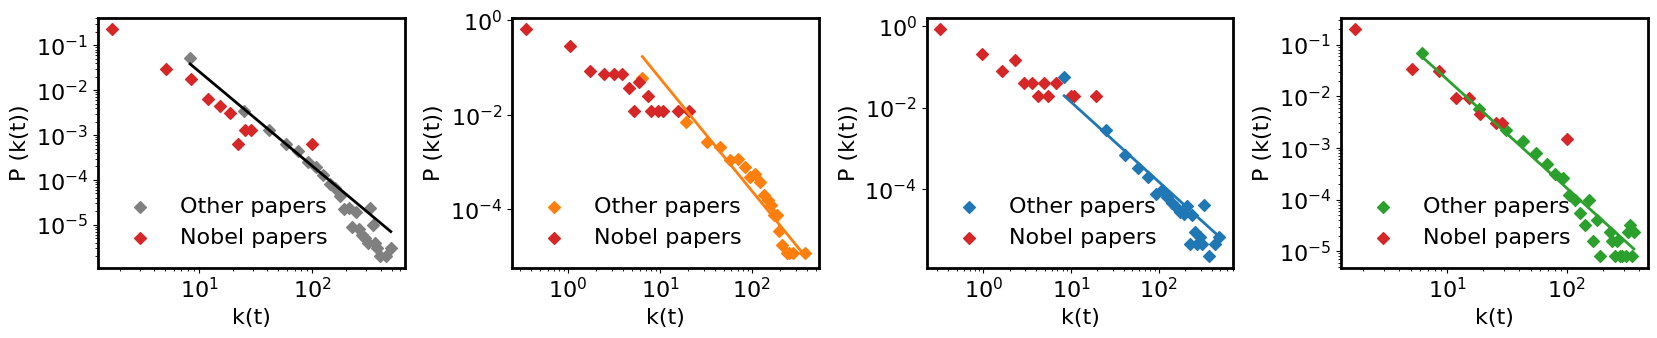

In [26]:
colors = ['tab:orange','tab:blue','tab:green']
fig = plt.figure(figsize=(20 , 12))
gs = gridspec.GridSpec(3, 4, figure=fig, wspace=.35, hspace=.35)
ax = fig.add_subplot(gs[0])

hist_values, bin_edges = np.histogram(df_[df_['Nobel_paper']==0]['b_cum_k'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='grey', marker='D', label='Other papers')
regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
plt.plot(bin_centers, fitted_line, color='k', linestyle='-', lw = 2)

hist_values, bin_edges = np.histogram(df_[df_['Nobel_paper']==1]['b_cum_k'].values, bins=30, density=True)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
plt.scatter(bin_centers, hist_values, color='tab:red', marker='D', label='Nobel papers')
# regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
# fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
# plt.plot(bin_centers, fitted_line, color='red', linestyle='-', lw = 2, label='Log-log fit')
set_fig_2(ax , xlabel='$k(t)$', ylabel='P ($k(t)$)', xlog=1, ylog=1, iflegend=1, legendloc=3)

for i,field in enumerate(['Physics','Chemistry','Medicine']):
    ax = fig.add_subplot(gs[i+1])
    hist_values, bin_edges = np.histogram(df_[df_['Field']==field][df_['Nobel_paper']==0]['b_cum_k'].values, bins=30, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    plt.scatter(bin_centers, hist_values, color=colors[i], marker='D', label='Other papers')
    regression = scipy.stats.linregress(np.log10(bin_centers+.00001), np.log10(hist_values+.00001))
    fitted_line = 10** (np.log10(bin_centers+.00001) * regression.slope + regression.intercept)
    plt.plot(bin_centers, fitted_line, color=colors[i], linestyle='-', lw = 2)
    
    hist_values, bin_edges = np.histogram(df_[df_['Field']==field][df_['Nobel_paper']==1]['b_cum_k'].values, bins=30, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    plt.scatter(bin_centers, hist_values, color='tab:red', marker='D', label='Nobel papers')
    set_fig_2(ax , xlabel='$k(t)$', ylabel='P ($k(t)$)', xlog=1, ylog=1, iflegend=1, legendloc=3)

In [6]:
df1 = df[df['Nobel_paper']==1].copy()
df1.index = range(len(df1))
df_contorl_t = df.merge(df1[['Focal_AID' , 't', 'paper_CD5']] , on = ['Focal_AID' , 't'])

In [7]:
df_ = df.groupby(['Focal_AID', 'Field', 'Nobel_paper' , 'PaperID'])['b_cum_k'].mean().reset_index()
df_contorl_t_ = df_contorl_t.groupby(['Focal_AID', 'Field', 'Nobel_paper' , 'PaperID'])['b_cum_k'].mean().reset_index()

In [12]:
def draw_p(data,col):
    t, p = scipy.stats.ttest_ind(data[data['Nobel_paper']==1][col].dropna(), data[data['Nobel_paper']==0][col].dropna(), equal_var=False, alternative='two-sided')
    if p>=0.05:
        ptext = 'p = '+str(np.around(p, 3))
    elif p<0.001:
        ptext = 'p < 0.001'
    elif p<0.01:
        ptext = 'p < 0.01'
    elif p<0.05:
        ptext = 'p < 0.05'


    b = max(np.mean(data[data['Nobel_paper']==0][col]) , np.mean(data[data['Nobel_paper']==1][col]))
    
    plt.text(0, np.mean(data[data['Nobel_paper']==0][col]) - b*0.1, 
             "{}".format(np.around(np.mean(data[data['Nobel_paper']==0][col]), 1)),c = 'white', fontsize=16, ha='center', fontweight='bold')
    plt.text(1, np.mean(data[data['Nobel_paper']==1][col]) - b*0.1,
             "{}".format(np.around(np.mean(data[data['Nobel_paper']==1][col]), 1)),c = 'white', fontsize=16, ha='center', fontweight='bold')
    
    plt.text(-0.1, b*1.15, "Welch's T = {}".format(np.around(t, 2)), fontsize=16)
    plt.text(0.15, b*1.05, ptext, fontsize=16)

C:\Users\nd\AppData\Local\Temp\ipykernel_21376\2359528299.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_, x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=['k','tab:red'])
C:\Users\nd\AppData\Local\Temp\ipykernel_21376\2359528299.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_[df_['Field']==field], x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=[colors[i],'tab:red'])
C:\Users\nd\AppData\Local\Temp\ipykernel_21376\2359528299.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `le

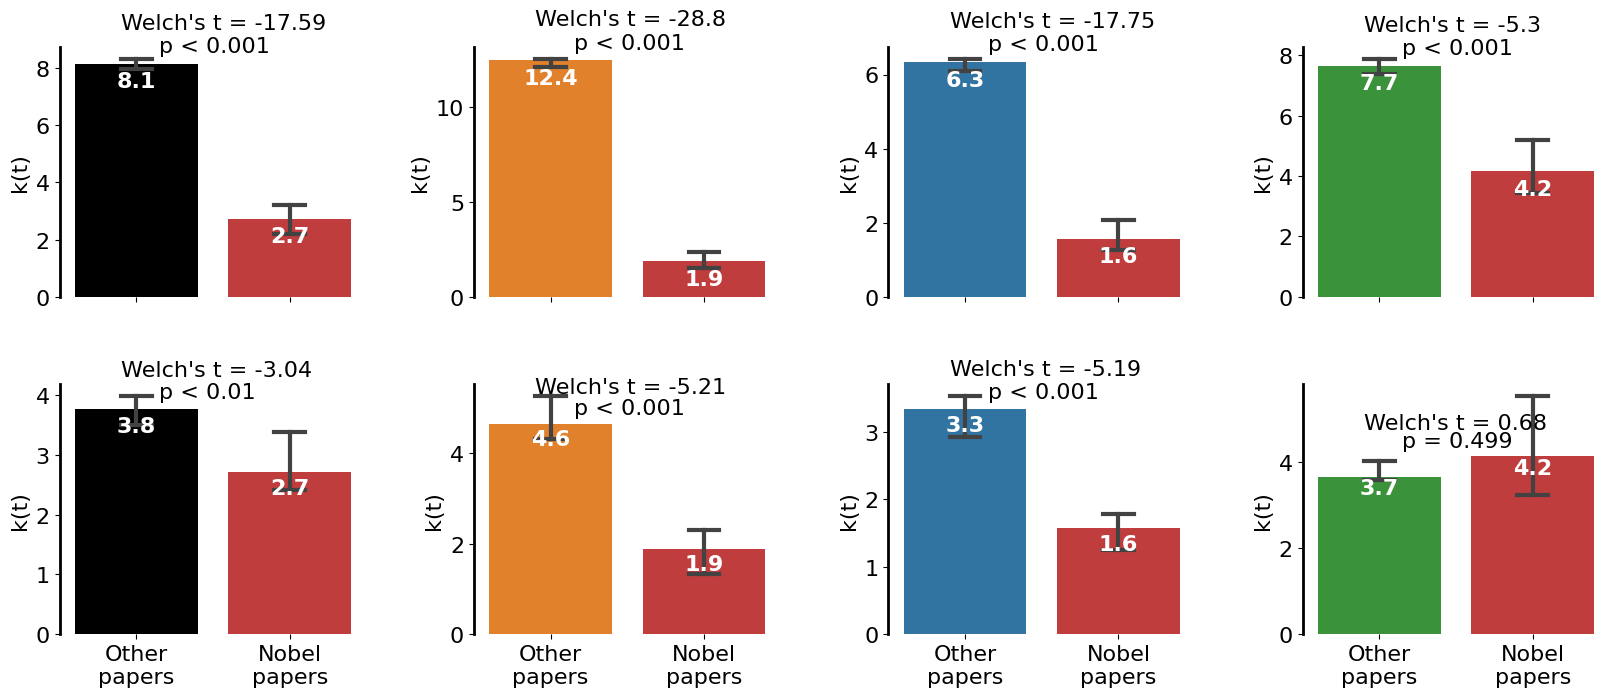

In [13]:
colors = ['tab:orange','tab:blue','tab:green']
fig = plt.figure(figsize=(20 , 12))
gs = gridspec.GridSpec(3, 4, figure=fig, wspace=.35, hspace=.35)
ax = fig.add_subplot(gs[0])
sns.barplot(data=df_, x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=['k','tab:red'])
plt.xticks([0,1],['',''])
# plt.ylim(0,40)
draw_p(df_,'b_cum_k')
set_fig_(ax , xlabel=0, ylabel='$k(t)$', xlog=0, ylog=0)

for i,field in enumerate(['Physics','Chemistry','Medicine']):
    ax = fig.add_subplot(gs[i+1])
    sns.barplot(data=df_[df_['Field']==field], x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=[colors[i],'tab:red'])
    plt.xticks([0,1],['',''])
    # plt.ylim(0,40)
    draw_p(df_[df_['Field']==field],'b_cum_k')
    set_fig_(ax , xlabel=0, ylabel='$k(t)$', xlog=0, ylog=0)

ax = fig.add_subplot(gs[4])
sns.barplot(data=df_contorl_t_, x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=['k','tab:red'])
plt.xticks([0,1],['Other\npapers','Nobel\npapers'])
draw_p(df_contorl_t_,'b_cum_k')
set_fig_(ax , xlabel=0, ylabel='$k(t)$', xlog=0, ylog=0)

for i,field in enumerate(['Physics','Chemistry','Medicine']):
    ax = fig.add_subplot(gs[i+5])
    sns.barplot(data=df_contorl_t_[df_contorl_t_['Field']==field], x='Nobel_paper', y = 'b_cum_k', err_kws={'linewidth': 3}, capsize=.2 , n_boot=10 , palette=[colors[i],'tab:red'])
    plt.xticks([0,1],['Other\npapers','Nobel\npapers'])
    draw_p(df_contorl_t_[df_contorl_t_['Field']==field],'b_cum_k')
    set_fig_(ax , xlabel=0, ylabel='$k(t)$', xlog=0, ylog=0)